# Лекция 11: Компьютерное зрение
## Адаптеры в диффузионных моделях & SOTA модели. Часть 4

**Преподаватель:** Шевченко Елена, Т-Банк

**Аудитория:** ФКН ВШЭ, МФТИ

---

## Содержание

1. ~~Адаптеры~~
   1. ~~Зачем нужны, типы адаптеров~~
   2. ~~ControlNet~~
   3. ~~IP-Adapter~~
   4. ~~InstantStyle: инъекция по блокам~~
   5. ~~Что ещё бывает~~
   6. ~~От адаптеров к in-context conditioning~~
2. ~~Как устроена современная text-to-image модель~~
   0. ~~Общая схема~~
   1. ~~Flow Matching~~
   2. ~~Картинка — это последовательность токенов~~
   3. ~~Скалярные условия — через adaLN~~
   4. ~~RoPE — позиции токенов~~
   5. ~~Текст — через joint attention~~
   6. ~~DoubleStream и SingleStream блоки~~
   7. ~~Референсы — это тоже токены~~
   8. ~~Меньше шагов~~
   9. ~~Итог~~
3. ~~Современные модели: FLUX и Qwen-Image~~
   1. ~~FLUX.1 — эталон~~
   2. ~~FLUX.1 Kontext — редактирование через референсы~~
   3. ~~FLUX.2 — больше, проще, с VLM~~
   4. ~~FLUX 3 Klein — маленькая и быстрая~~
   5. ~~Qwen-Image — другая ветка~~
   6. ~~Закрытые модели~~
   7. ~~Итог~~
4. **Дистилляция** (этот ноутбук)
   0. Сколько стоит генерация
   1. Guidance distillation — один проход вместо двух
   2. Step и progressive distillation
   3. ADD и LADD
   4. DMD и DMD2
   5. Consistency, MeanFlow, flow map
   6. Модели
   7. Итог

---

В 11-3 у каждой модели была быстрая версия: FLUX.1 [schnell] — 1–4 шага, FLUX.2 [klein] — 4, FLUX 3 Klein distilled — 16 без CFG, Qwen-Image-2.0 — 4. Здесь — как их получают; в конце — ещё один пример, Z-Image-Turbo (8 шагов).

## 0. Сколько стоит генерация

Цена генерации — число вызовов сети (NFE, number of function evaluations):

$$\text{NFE} = N_{\text{шагов}} \times \begin{cases} 2, & \text{с CFG} \\ 1, & \text{без CFG} \end{cases}$$

FLUX.1 без ускорения — 50 шагов с CFG, то есть 100 проходов 12B-сети. Отсюда два независимых способа ускорить:

- **убрать второй проход** на каждом шаге — guidance distillation, ×2;
- **уменьшить число шагов** — всё остальное в этой лекции, ×10 и больше.

Во всех методах есть **учитель** — обычная обученная модель, она заморожена, — и **студент**. Студента инициализируют весами учителя и дообучают делать то же самое дешевле. Методы отличаются тем, *что именно* студент должен повторить.

## 1. Guidance distillation — один проход вместо двух

CFG делает на каждом шаге два прохода — с промптом и без:

$$v_{\text{cfg}} = v_\theta(x_t, t, \varnothing) + g \cdot \big(v_\theta(x_t, t, \text{text}) - v_\theta(x_t, t, \varnothing)\big)$$

### Идея

Научить студента выдавать $v_{\text{cfg}}$ за один проход, подав масштаб $g$ на вход.

### Обучение
1. Берём картинку $x_0$, промпт, случайные $t$, $\epsilon$ и $g$ из диапазона (например, от 1 до 7). Строим $x_t = (1 - t)\, x_0 + t\, \epsilon$.
2. Учитель делает два прохода и считает $v_{\text{cfg}}$ — это цель.
3. Студент делает один проход: $v_{\text{student}} = v_\phi(x_t, t, \text{text}, g)$.
4. Лосс:

$$\mathcal{L} = \big\| v_{\text{student}} - v_{\text{cfg}} \big\|^2$$

### Что меняется в архитектуре

Только вектор условия для adaLN — к эмбеддингу $t$ прибавляется эмбеддинг $g$:

$$c = \text{MLP}_t(t) + \text{MLP}_g(g)$$

У FLUX.1 к этому прибавляется ещё pooled-вектор CLIP (11-3).

### Цена

Безусловного прохода больше нет, поэтому negative prompt не работает.

### Где

FLUX.1 [dev] ($g$ по умолчанию 3.5), FLUX.2 [dev] ($g$ по умолчанию 4.0); внешний CFG выключен.

## 2. Step и progressive distillation — повторить траекторию учителя

![prog-d](assets/distillation_progressive.png)

*Один шаг студента повторяет $K = 2$ шага учителя. Нотация рисунка — как в DDPM: $x_T$ — шум, $x_0$ — картинка.*

### Идея

Один большой шаг студента должен попасть туда же, куда учитель приходит за несколько маленьких.

Пусть учитель делает $K$ шагов Эйлера размера $\Delta t$ из точки $x_t$ и приходит в $x_{\text{target}}$ (без градиента). Студент делает один шаг размера $K \Delta t$:

$$x_{\text{student}} = x_t - K\Delta t \cdot v_\phi(x_t, t), \qquad \mathcal{L} = \big\| x_{\text{student}} - x_{\text{target}} \big\|^2$$

Лосс — не по скорости, а по точке, куда пришли.

![step-d](assets/distillation_step.png)

*Крайний случай — весь путь учителя за один шаг студента.*

### Progressive distillation

Сразу учить «50 шагов за 4» плохо: учитель за 12 шагов проходит заметно искривлённый путь, и один прямой шаг в него не попадает. Поэтому сжимают по 2 шага за раз:

```
раунд 1: учитель 50 шагов → студент учится делать 2 шага за 1 → 25 шагов
раунд 2: студент из раунда 1 становится учителем        → 12 шагов
раунд 3: …                                                → 6
раунд 4: …                                                → 3–4
```

Каждый раунд — маленький прыжок, который легко выучить; ошибки накапливаются постепенно.

### Ограничение

Студент повторяет учителя, поэтому не может стать лучше его. При 1–4 шагах картинки получаются размытыми: усреднённый ответ на неопределённый вопрос «куда идти из шума» — это среднее по многим картинкам.

## 3. ADD и LADD — обмануть дискриминатор

Размытость из прошлого раздела — та же проблема, что у MSE в генерации вообще. Классическое решение — adversarial loss: дискриминатор штрафует за всё, что не похоже на настоящую картинку.

### ADD — Adversarial Diffusion Distillation (Stability AI, 2023, SDXL-Turbo)

![add](assets/add.jpg)

Студент генерирует картинку за 1–4 шага. Лосс из двух частей:

$$\mathcal{L} = \mathcal{L}_{\text{adv}} + \lambda\, \mathcal{L}_{\text{distill}}$$

- $\mathcal{L}_{\text{adv}}$ — дискриминатор отличает картинки студента от реальных. Признаки для него даёт замороженный DINOv2, обучаются только маленькие головы поверх.
- $\mathcal{L}_{\text{distill}}$ — выход студента зашумляют, учитель его «расшумляет», и студент должен совпасть с этим ответом. Это держит студента рядом с учителем.

#### Проблемы

DINOv2 работает с пикселями — на каждом шаге обучения латент надо декодировать VAE, это дорого по памяти. И DINOv2 обучен на 518 × 518, высокие разрешения не тянет.

### LADD — Latent ADD (Stability AI, 2024, SD3-Turbo)

![ladd](assets/ladd.jpg)

#### Изменение 1: дискриминатор — это сам учитель

Выход студента зашумляют и прогоняют через замороженного учителя. После каждого attention-блока берут токены и подают в свою маленькую голову $D_k$ (2D-свёртки, условие — уровень шума и текст). Всё в латенте, декодировать не нужно.

Что оценивает дискриминатор, зависит от уровня шума на входе учителя: при сильном шуме — композицию, при слабом — детали. Распределением уровней шума при обучении сдвигают акцент между ними. Головы стоят на всех блоках, их сигналы суммируются:

$$\mathcal{L}_D = -\sum_k \mathbb{E}\big[\log D_k(F_k^{\text{real}})\big] - \sum_k \mathbb{E}\big[\log\big(1 - D_k(F_k^{\text{fake}})\big)\big], \qquad \mathcal{L}_{\text{student}} = -\sum_k \mathbb{E}\big[\log D_k(F_k^{\text{fake}})\big]$$

где $F_k$ — признаки $k$-го блока учителя на зашумлённой реальной ($\text{real}$) или сгенерированной ($\text{fake}$) картинке.

#### Изменение 2: «реальные» картинки генерирует учитель

Учитель генерирует их с фиксированным CFG. Так студент учится повторять именно учителя, и отдельный $\mathcal{L}_{\text{distill}}$ становится не нужен — авторы обучают только adversarial-лоссом. На реальных данных в их экспериментах получилось хуже.

Обучение поочерёдное: шаг обновления голов $D_k$ (студент заморожен), шаг обновления студента (головы заморожены). Учитель заморожен всегда.

| | ADD | LADD |
|---|---|---|
| дискриминатор | головы на DINOv2 | головы на учителе |
| пространство | пиксели | латент |
| данные | реальные | от учителя |
| лосс | adversarial + distill | только adversarial |
| пример | SDXL-Turbo | SD3-Turbo, FLUX.1 [schnell] |

## 4. DMD и DMD2 — совпасть с учителем по распределению

### Идея

Не требовать, чтобы студент из конкретного шума $\epsilon$ получил конкретную картинку учителя. Достаточно, чтобы *распределение* картинок студента совпало с распределением картинок учителя. Это мягче, поэтому студент может делать 1–4 шага и не размываться.

Как измерить, что два распределения совпали, если у нас есть только сэмплы? Через score — направление, в котором растёт плотность. Нужны две модели:

- $s_{\text{real}}$ — score распределения учителя. Это и есть сам учитель (скорость Flow Matching и score однозначно пересчитываются друг в друга), причём с CFG при фиксированном масштабе — так guidance «вшивается» в студента.
- $s_{\text{fake}}$ — score распределения студента. Это вторая диффузионная модель, которую **параллельно учат** обычным диффузионным лоссом на картинках студента.

Студент $G_\phi$ превращает шум в картинку $x = G_\phi(\epsilon)$. Картинку зашумляем до $x_t$. Градиент KL между распределениями:

$$\nabla_\phi\, \text{KL} \approx \mathbb{E}_{\epsilon, t}\Big[\, w_t\, \big(s_{\text{fake}}(x_t, t) - s_{\text{real}}(x_t, t)\big)\, \frac{\partial x}{\partial \phi} \,\Big]$$

$w_t$ — нормирующий вес, который выравнивает вклад разных уровней шума $t$.

Как читать: $s_{\text{real}}$ тянет картинку туда, где плотность учителя выше; $s_{\text{fake}}$ отталкивает от того места, где студент уже и так генерирует — это не даёт ему схлопнуться в одну картинку.

### DMD (2023)

DMD добавлял ещё регрессию на пары «шум → картинка учителя» для стабильности — для этого заранее генерировали большой датасет пар.

### DMD2 (2024)
- регрессию убрали — датасет пар больше не нужен;
- $s_{\text{fake}}$ обновляют в несколько раз чаще студента, чтобы он успевал за студентом;
- добавили GAN-лосс на признаках $s_{\text{fake}}$ и реальных картинках — студент может стать лучше учителя;
- студент делает несколько шагов, и при обучении ему подают его собственные промежуточные результаты, а не точки с траектории учителя.

### Где

Qwen-Image-2.0 (учитель 40 шагов → студент 4), Z-Image-Turbo (8 шагов).

## 5. Consistency, MeanFlow, flow map — выучить сразу прыжок

Все методы выше учат студента «как-то» попадать в хорошие картинки за мало шагов. Другой подход: выучить не мгновенную скорость, а сразу **отображение «из точки $x_t$ в точку $x_s$»** для любых $t$ и $s$. Тогда число шагов выбирается при генерации.

В лекции 10 был Reflow — он выпрямляет траектории, чтобы Эйлер с большим шагом ошибался меньше. Здесь идея другая: траектории остаются кривыми, но сеть сразу знает, куда приведёт большой шаг.

### Consistency models (2023)

Сеть $f_\theta(x_t, t)$ из любой точки траектории сразу предсказывает её конец — чистую картинку. Обучение — требование согласованности: две соседние точки одной траектории должны давать один ответ:

$$f_\theta(x_t, t) = f_{\theta^-}(x_{t'}, t'), \qquad t' < t$$

$\theta^-$ — EMA-копия весов. Чтобы сеть не выучила тривиальный ответ, добавляют граничное условие $f_\theta(x_0, 0) = x_0$: в чистой точке сеть ничего не меняет (его закладывают прямо в параметризацию сети).

Откуда берётся $x_{t'}$: в consistency distillation — один шаг ODE-решателя учителя из $x_t$; в consistency training (без учителя) — та же картинка $x_0$, зашумлённая тем же $\epsilon$ до уровня $t'$.

Генерация — 1–2 шага. **sCM** (2024) — непрерывная по времени версия, которая стабильно масштабируется на большие модели.

### MeanFlow (2025)

Вместо мгновенной скорости $v$ сеть учит **среднюю скорость** на отрезке $[s, t]$:

$$u(x_t, s, t) = \frac{1}{t - s} \int_s^t v(x_\tau, \tau)\, d\tau, \qquad x_s = x_t - (t - s)\, u(x_t, s, t)$$

Интеграл посчитать нельзя, но из определения следует тождество, которое можно использовать как лосс:

$$u(x_t, s, t) = v(x_t, t) - (t - s)\, \frac{d}{dt} u(x_t, s, t)$$

Здесь $\frac{d}{dt}$ — полная производная вдоль траектории: $\frac{d}{dt} u = v\, \partial_x u + \partial_t u$. Её считают одним JVP-проходом, а правую часть тождества используют как цель со stop-grad.

При $s = t$ это обычный Flow Matching. Модель можно учить с нуля, без учителя; генерация — 1 шаг.

### Flow map во FLUX 3 Klein distilled

Та же идея, что в MeanFlow: сеть получает текущее $t$ и целевое $s$ (`target_timestep`) и делает шаг

$$x_s = x_t - (t - s)\, u_\theta(x_t, s, t), \qquad s < t$$

16 шагов без CFG. Как именно BFL обучала Klein, не раскрыто.

## 6. Модели

![schnell](assets/schnell.jpeg)

| модель | шагов | метод |
|---|---|---|
| FLUX.1 [dev] | 20–50 | guidance distillation |
| FLUX.1 [schnell] | 1–4 | LADD |
| SD3-Turbo | 1–4 | LADD |
| FLUX.2 [klein] distilled | 4 | дистилляция по шагам и guidance (метод не раскрыт) |
| Z-Image-Turbo | 8 | Decoupled DMD + RL |
| Qwen-Image-2.0 | 4 | DMD |
| FLUX 3 Klein distilled | 16 | flow map, без CFG |

### Почему у дистиллированных моделей не работает CFG

CFG уже «вшит»: при дистилляции учитель работал с фиксированным guidance, и студент выучил уже усиленный результат. Повторное усиление пересвечивает картинку. У FLUX.1 [schnell] guidance-эмбеддинга вообще нет.

### Почему LoRA учат на base-версии

Дистилляция «запекает» в веса короткую траекторию. Дообучение обычным лоссом её ломает. Поэтому BFL выпускает пары base / distilled (FLUX.2 [klein], FLUX 3 Klein): LoRA учат на base. У FLUX.1 base-версии нет: LoRA учат на [dev] — guidance distillation убирает только второй проход и траекторию не укорачивает; на [schnell] LoRA учить плохо.

### Z-Image-Turbo (Alibaba Tongyi-MAI, конец 2025)

![z-image](assets/z-image.png)

6B, single-stream DiT: текст и картинка в одной последовательности с первого блока. 8 шагов. Дистилляция — Decoupled DMD: авторы показали, что основную работу в DMD делает «вшитый» CFG, а сопоставление распределений служит регуляризатором. Поверх — DMDR: RL с наградами, обучаемый одновременно с DMD.

## 7. Итог

| метод | что повторяет студент | дискриминатор | шагов |
|---|---|---|---|
| guidance distillation | выход CFG учителя | нет | как у учителя, ×2 быстрее |
| progressive | точку после 2 шагов учителя | нет | 4–8 |
| ADD / LADD | «реалистичность» по мнению дискриминатора | да | 1–4 |
| DMD / DMD2 | распределение учителя | нет / да | 1–4 |
| consistency, MeanFlow, flow map | прыжок из $t$ в $s$ | нет | 1–16 |

Как выбирают: guidance distillation делают почти всегда — это бесплатные ×2. Для 1–4 шагов — adversarial или DMD: без них картинка размыта. Flow map — когда нужна одна модель на любое число шагов.

## Источники

- Guidance distillation: Meng et al., On Distillation of Guided Diffusion Models, https://arxiv.org/abs/2210.03142
- Progressive distillation: https://arxiv.org/abs/2202.00512
- ADD: https://arxiv.org/abs/2311.17042; LADD: https://arxiv.org/abs/2403.12015
- DMD: https://arxiv.org/abs/2311.18828; DMD2: https://arxiv.org/abs/2405.14867
- Consistency models: https://arxiv.org/abs/2303.01469; sCM: https://arxiv.org/abs/2410.11081
- MeanFlow: https://arxiv.org/abs/2505.13447
- Z-Image: https://arxiv.org/abs/2511.22699; Decoupled DMD: https://arxiv.org/abs/2511.22677; DMDR: https://arxiv.org/abs/2511.13649
- Qwen-Image-2.0: https://arxiv.org/abs/2605.10730
- FLUX 3 Klein: https://huggingface.co/black-forest-labs/flux-3-image-klein

## Демо: SDXL vs SDXL-Turbo

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

model_index.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/459 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

... (11 outputs left out)

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/10.3G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

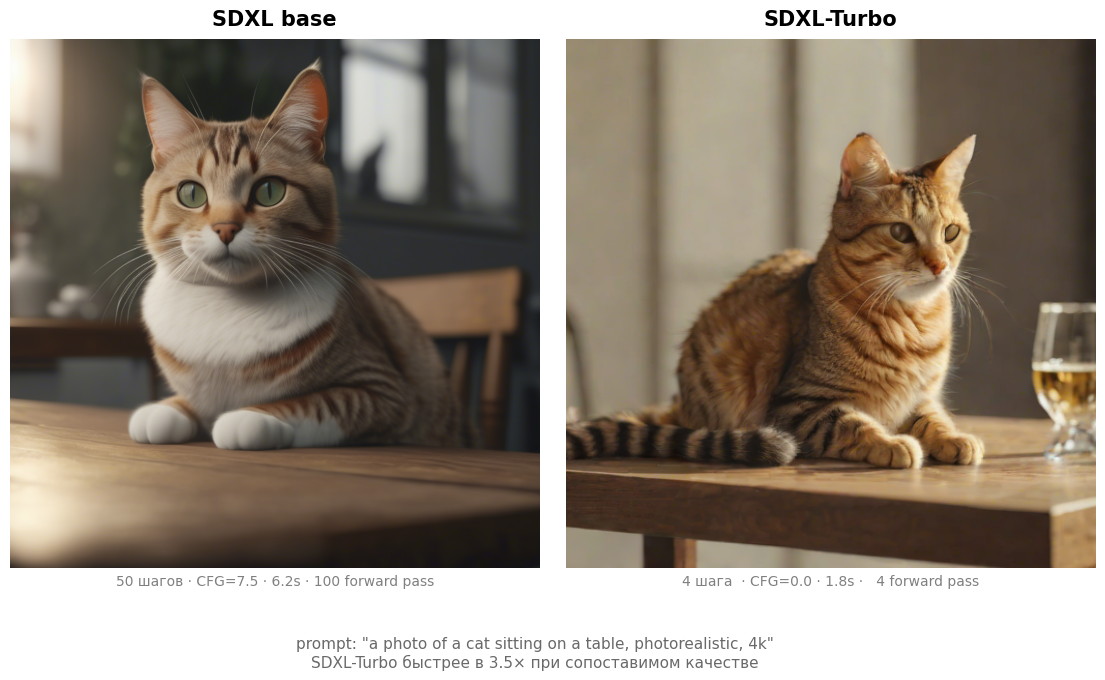

In [1]:
import torch
from diffusers import StableDiffusionXLPipeline
import time
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

prompt = "a photo of a cat sitting on a table, photorealistic, 4k"
SEED = 42


def timed(pipe, **kwargs):
    """Прогрев (первый вызов включает инициализацию CUDA) + замер второго вызова."""
    pipe(prompt=prompt, num_inference_steps=1, **{k: v for k, v in kwargs.items() if k != "num_inference_steps"})
    torch.cuda.synchronize()
    t0 = time.time()
    image = pipe(prompt=prompt, generator=torch.Generator("cuda").manual_seed(SEED), **kwargs).images[0]
    torch.cuda.synchronize()
    return image, time.time() - t0


# --- SDXL оригинал: родное разрешение 1024×1024 ---
pipe_base = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16,
).to("cuda")
image_base, time_base = timed(pipe_base, num_inference_steps=50, guidance_scale=7.5)

del pipe_base
torch.cuda.empty_cache()

# --- SDXL-Turbo дистиллят: родное разрешение 512×512 ---
pipe_turbo = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/sdxl-turbo",
    torch_dtype=torch.float16,
).to("cuda")
image_turbo, time_turbo = timed(pipe_turbo, num_inference_steps=4, guidance_scale=0.0)

del pipe_turbo
torch.cuda.empty_cache()

# --- визуализация ---
fig = plt.figure(figsize=(14, 7))
gs = gridspec.GridSpec(1, 2, wspace=0.05)

for idx, (img, title, subtitle) in enumerate([
    (image_base,  "SDXL base",  f"{image_base.width}² · 50 шагов · CFG=7.5 · {time_base:.1f}s · 100 forward pass"),
    (image_turbo, "SDXL-Turbo", f"{image_turbo.width}² · 4 шага · CFG=0.0 · {time_turbo:.1f}s · 4 forward pass"),
]):
    ax = fig.add_subplot(gs[idx])
    ax.imshow(img)
    ax.set_title(title, fontsize=15, fontweight="bold", pad=10)
    ax.set_xlabel(subtitle, fontsize=10, color="gray")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

speedup = time_base / time_turbo
fig.suptitle(
    f'prompt: "{prompt}"\n'
    f"SDXL-Turbo быстрее в {speedup:.1f}× — за счёт числа проходов (4 против 100) "
    f"и в 4 раза меньшего числа пикселей (512² против 1024²)",
    fontsize=11,
    y=0.02,
    color="dimgray",
)

plt.savefig("sdxl_vs_turbo.png", dpi=150, bbox_inches="tight")
plt.show()